In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split



In [2]:
df_customers = pd.read_csv('customers.csv')
df_loans = pd.read_csv('loans.csv')
df_bureau = pd.read_csv('bureau_data.csv')

In [3]:
df_customers.shape, df_loans.shape, df_bureau.shape

((50000, 12), (50000, 15), (50000, 8))

In [4]:
df_customers.head(2)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,state,zipcode
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,Delhi,110001
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,Tamil Nadu,600001


In [5]:
df_loans.head(2)

,loan_id,cust_id,loan_purpose,loan_type,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
0,L00001,C00001,Auto,Secured,3004000,2467000,49340.0,444060,1973600,33,1630408,873386,2019-07-24,2019-08-10,False
1,L00002,C00002,Home,Secured,4161000,3883000,77660.0,698940,3106400,30,709309,464100,2019-07-24,2019-08-15,False


In [6]:
df = pd.merge(df_customers, df_loans, on='cust_id')
df.head(2)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,...,2467000,49340.0,444060,1973600,33,1630408,873386,2019-07-24,2019-08-10,False
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,...,3883000,77660.0,698940,3106400,30,709309,464100,2019-07-24,2019-08-15,False


In [7]:
df_bureau.head(2)

,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
0,C00001,1,1,42,0,0,3,7
1,C00002,3,1,96,12,60,5,4


In [8]:
df = pd.merge(df, df_bureau, on='cust_id')
df.head(2)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,default,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,...,2019-07-24,2019-08-10,False,1,1,42,0,0,3,7
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,...,2019-07-24,2019-08-15,False,3,1,96,12,60,5,4


In [9]:
df['default'] = df['default'].astype('int')
df.head(2)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,default,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,...,2019-07-24,2019-08-10,0,1,1,42,0,0,3,7
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,...,2019-07-24,2019-08-15,0,3,1,96,12,60,5,4


In [10]:
X = df.drop([ 'default'], axis=1)
y = df['default']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=40)

df_train = pd.concat([X_train, y_train], axis=1)
df_test = pd.concat([X_test, y_test], axis=1)

In [11]:
df_train.shape , df_test.shape

((40000, 33), (10000, 33))

In [12]:
df_train.isna().sum()

cust_id                         0
age                             0
gender                          0
marital_status                  0
employment_status               0
income                          0
number_of_dependants            0
residence_type                 48
years_at_current_address        0
city                            0
state                           0
zipcode                         0
loan_id                         0
loan_purpose                    0
loan_type                       0
sanction_amount                 0
loan_amount                     0
processing_fee                  0
gst                             0
net_disbursement                0
loan_tenure_months              0
principal_outstanding           0
bank_balance_at_application     0
disbursal_date                  0
installment_start_dt            0
number_of_open_accounts         0
number_of_closed_accounts       0
total_loan_months               0
delinquent_months               0
total_dpd     

In [13]:
df_train.residence_type.unique()

<ArrowStringArray>
['Owned', 'Rented', 'Mortgage', nan]
Length: 4, dtype: str

In [14]:
mode_residence = df_train.residence_type.mode()[0]
mode_residence

'Owned'

In [15]:
df_train.fillna(mode_residence, inplace=True)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default
33649,C33650,37,M,Married,Salaried,1061000,3,Owned,26,Kolkata,...,2022-12-03,2023-01-02,1,0,19,0,0,1,31,0
43700,C43701,42,M,Single,Salaried,283000,0,Owned,3,Ahmedabad,...,2023-12-05,2023-12-11,3,0,166,4,23,3,17,0
27039,C27040,52,F,Single,Self-Employed,207000,2,Owned,18,Mumbai,...,2022-04-06,2022-04-07,3,0,77,0,0,4,18,0
23128,C23129,35,M,Single,Self-Employed,7549000,0,Owned,21,Lucknow,...,2021-11-14,2021-11-24,2,1,46,4,28,4,75,0
35305,C35306,38,M,Single,Salaried,2096000,0,Rented,16,Pune,...,2023-02-02,2023-02-28,1,2,37,12,73,6,37,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27640,C27641,38,M,Married,Self-Employed,8355000,2,Owned,30,Mumbai,...,2022-04-28,2022-05-06,1,0,60,0,0,2,16,0
14501,C14502,40,M,Married,Self-Employed,1365000,3,Owned,24,Pune,...,2021-01-03,2021-01-15,1,2,12,9,52,1,70,0
30727,C30728,31,F,Single,Self-Employed,1323000,1,Mortgage,22,Pune,...,2022-08-19,2022-09-03,1,2,3,1,4,3,99,1
47323,C47324,41,F,Single,Self-Employed,904000,2,Mortgage,13,Lucknow,...,2024-04-15,2024-05-04,1,2,48,4,23,3,7,0


In [16]:
df_train.residence_type.unique()

<ArrowStringArray>
['Owned', 'Rented', 'Mortgage']
Length: 3, dtype: str

In [17]:
df_test.residence_type.unique()


<ArrowStringArray>
['Owned', 'Mortgage', 'Rented', nan]
Length: 4, dtype: str

In [18]:
mode_for_test = df_test.residence_type.mode()[0]   
mode_for_test 

'Owned'

In [19]:
df_test.fillna(mode_for_test, inplace=True)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default
22599,C22600,30,F,Single,Salaried,125000,0,Owned,22,Ahmedabad,...,2021-10-26,2021-10-29,4,2,120,0,0,8,24,0
38540,C38541,18,M,Single,Self-Employed,10253000,0,Owned,15,Delhi,...,2023-05-31,2023-06-20,2,1,51,0,0,2,98,0
32995,C32996,33,M,Single,Salaried,493000,0,Owned,7,Chennai,...,2022-11-09,2022-11-20,3,2,84,0,0,6,68,0
37372,C37373,36,M,Single,Self-Employed,11812000,0,Mortgage,20,Chennai,...,2023-04-18,2023-05-14,3,1,93,0,0,7,39,0
26774,C26775,40,F,Married,Salaried,714000,4,Owned,8,Jaipur,...,2022-03-27,2022-04-26,4,1,68,0,0,5,69,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1460,C01461,38,M,Single,Salaried,1388000,0,Owned,30,Hyderabad,...,2019-09-15,2019-10-03,3,2,115,0,0,3,2,0
962,C00963,41,M,Married,Salaried,2219000,3,Rented,2,Bangalore,...,2019-08-28,2019-09-25,3,0,78,11,69,8,71,0
15554,C15555,49,M,Married,Self-Employed,903000,4,Mortgage,15,Pune,...,2021-02-11,2021-02-28,2,2,80,10,69,6,77,1
27631,C27632,48,F,Single,Self-Employed,2811000,1,Mortgage,10,Chennai,...,2022-04-28,2022-05-08,3,1,131,12,53,8,79,0


In [20]:
df_train.duplicated().sum()

np.int64(0)

In [21]:
df_train.columns

Index(['cust_id', 'age', 'gender', 'marital_status', 'employment_status',
       'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio', 'default'],
      dtype='str')

In [32]:
# Numerical columns
numerical_cols =  ['age', 'income', 'number_of_dependants', 'years_at_current_address', 
                      'sanction_amount', 'loan_amount', 'processing_fee', 'gst', 'net_disbursement', 
                      'loan_tenure_months','principal_outstanding', 'bank_balance_at_application',
                      'number_of_open_accounts','number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
                       'total_dpd', 'enquiry_count', 'credit_utilization_ratio']

# Categorical columns
categorical_cols = ['gender', 'marital_status', 'employment_status', 'residence_type', 'city', 
                       'state', 'zipcode', 'loan_purpose', 'loan_type', 'default']

print("Numerical Columns:")
print(numerical_cols)


Numerical Columns:
['age', 'income', 'number_of_dependants', 'years_at_current_address', 'sanction_amount', 'loan_amount', 'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months', 'principal_outstanding', 'bank_balance_at_application', 'number_of_open_accounts', 'number_of_closed_accounts', 'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count', 'credit_utilization_ratio']


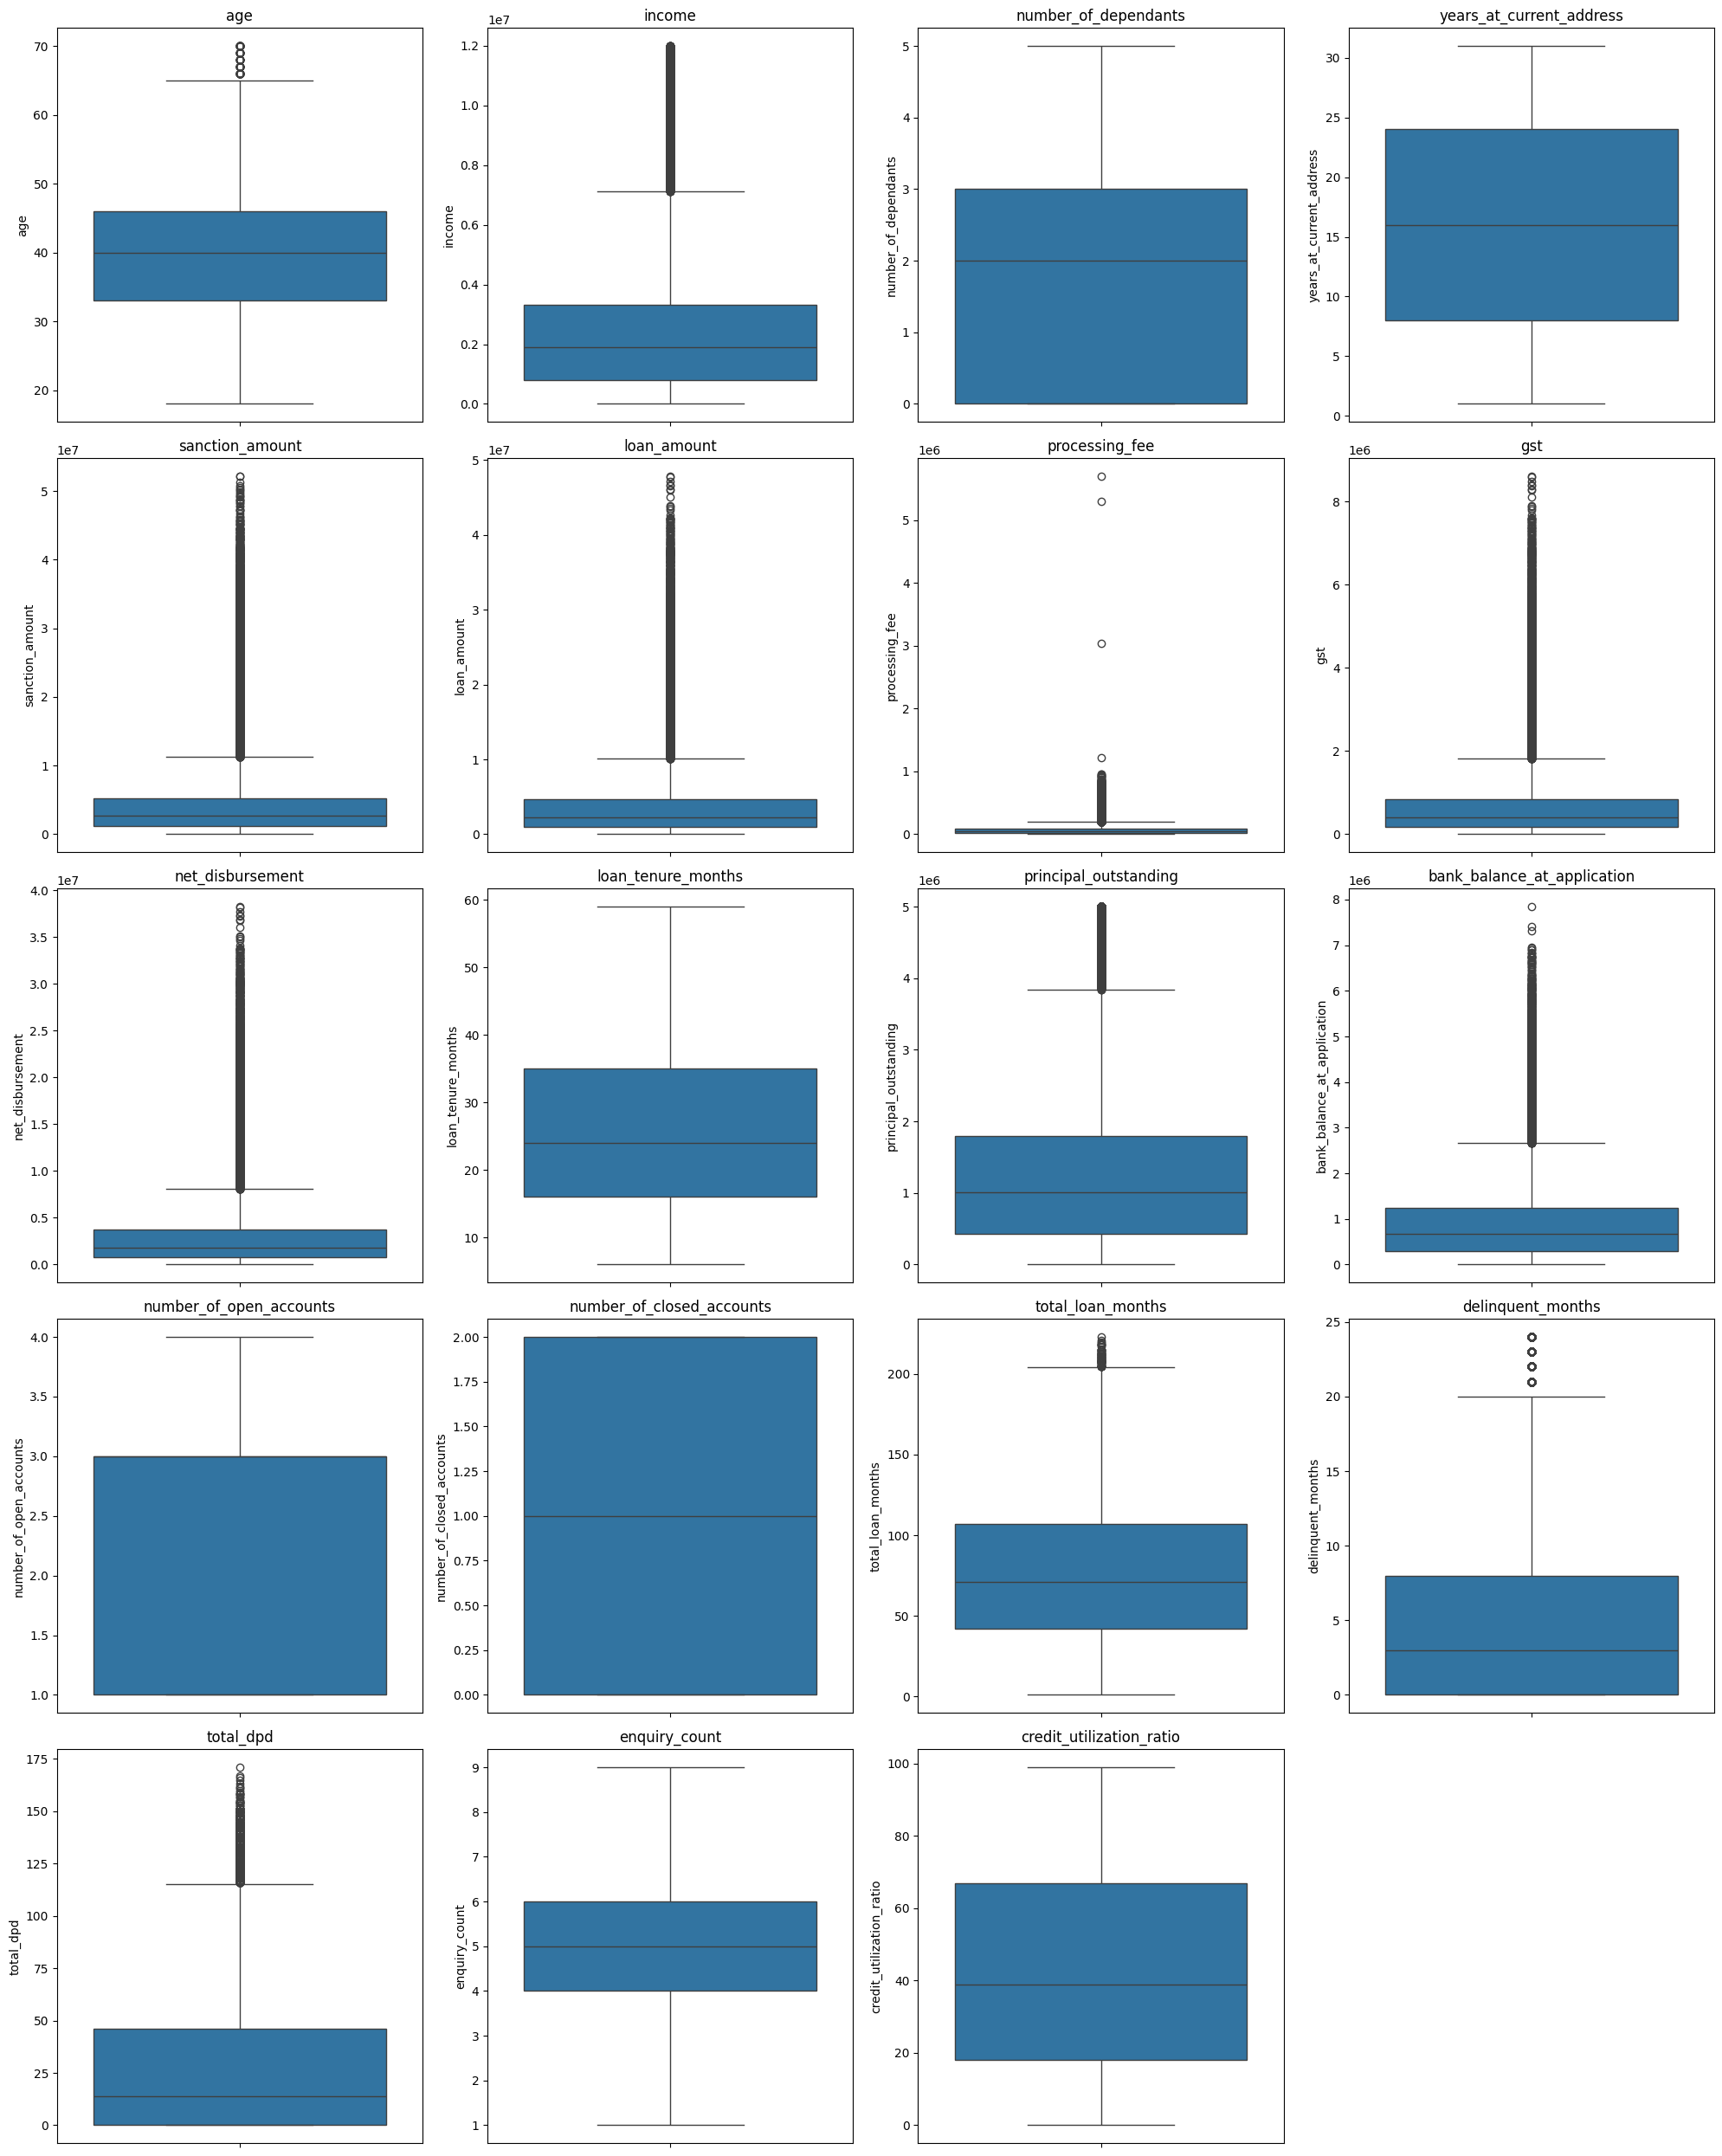

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

n_cols = 4
n_rows = math.ceil(len(numerical_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5 * n_rows))

axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.boxplot(df_train[col], ax=axes[i])
    axes[i].set_title(col)

# Remove empty plots
for i in range(len(numerical_cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

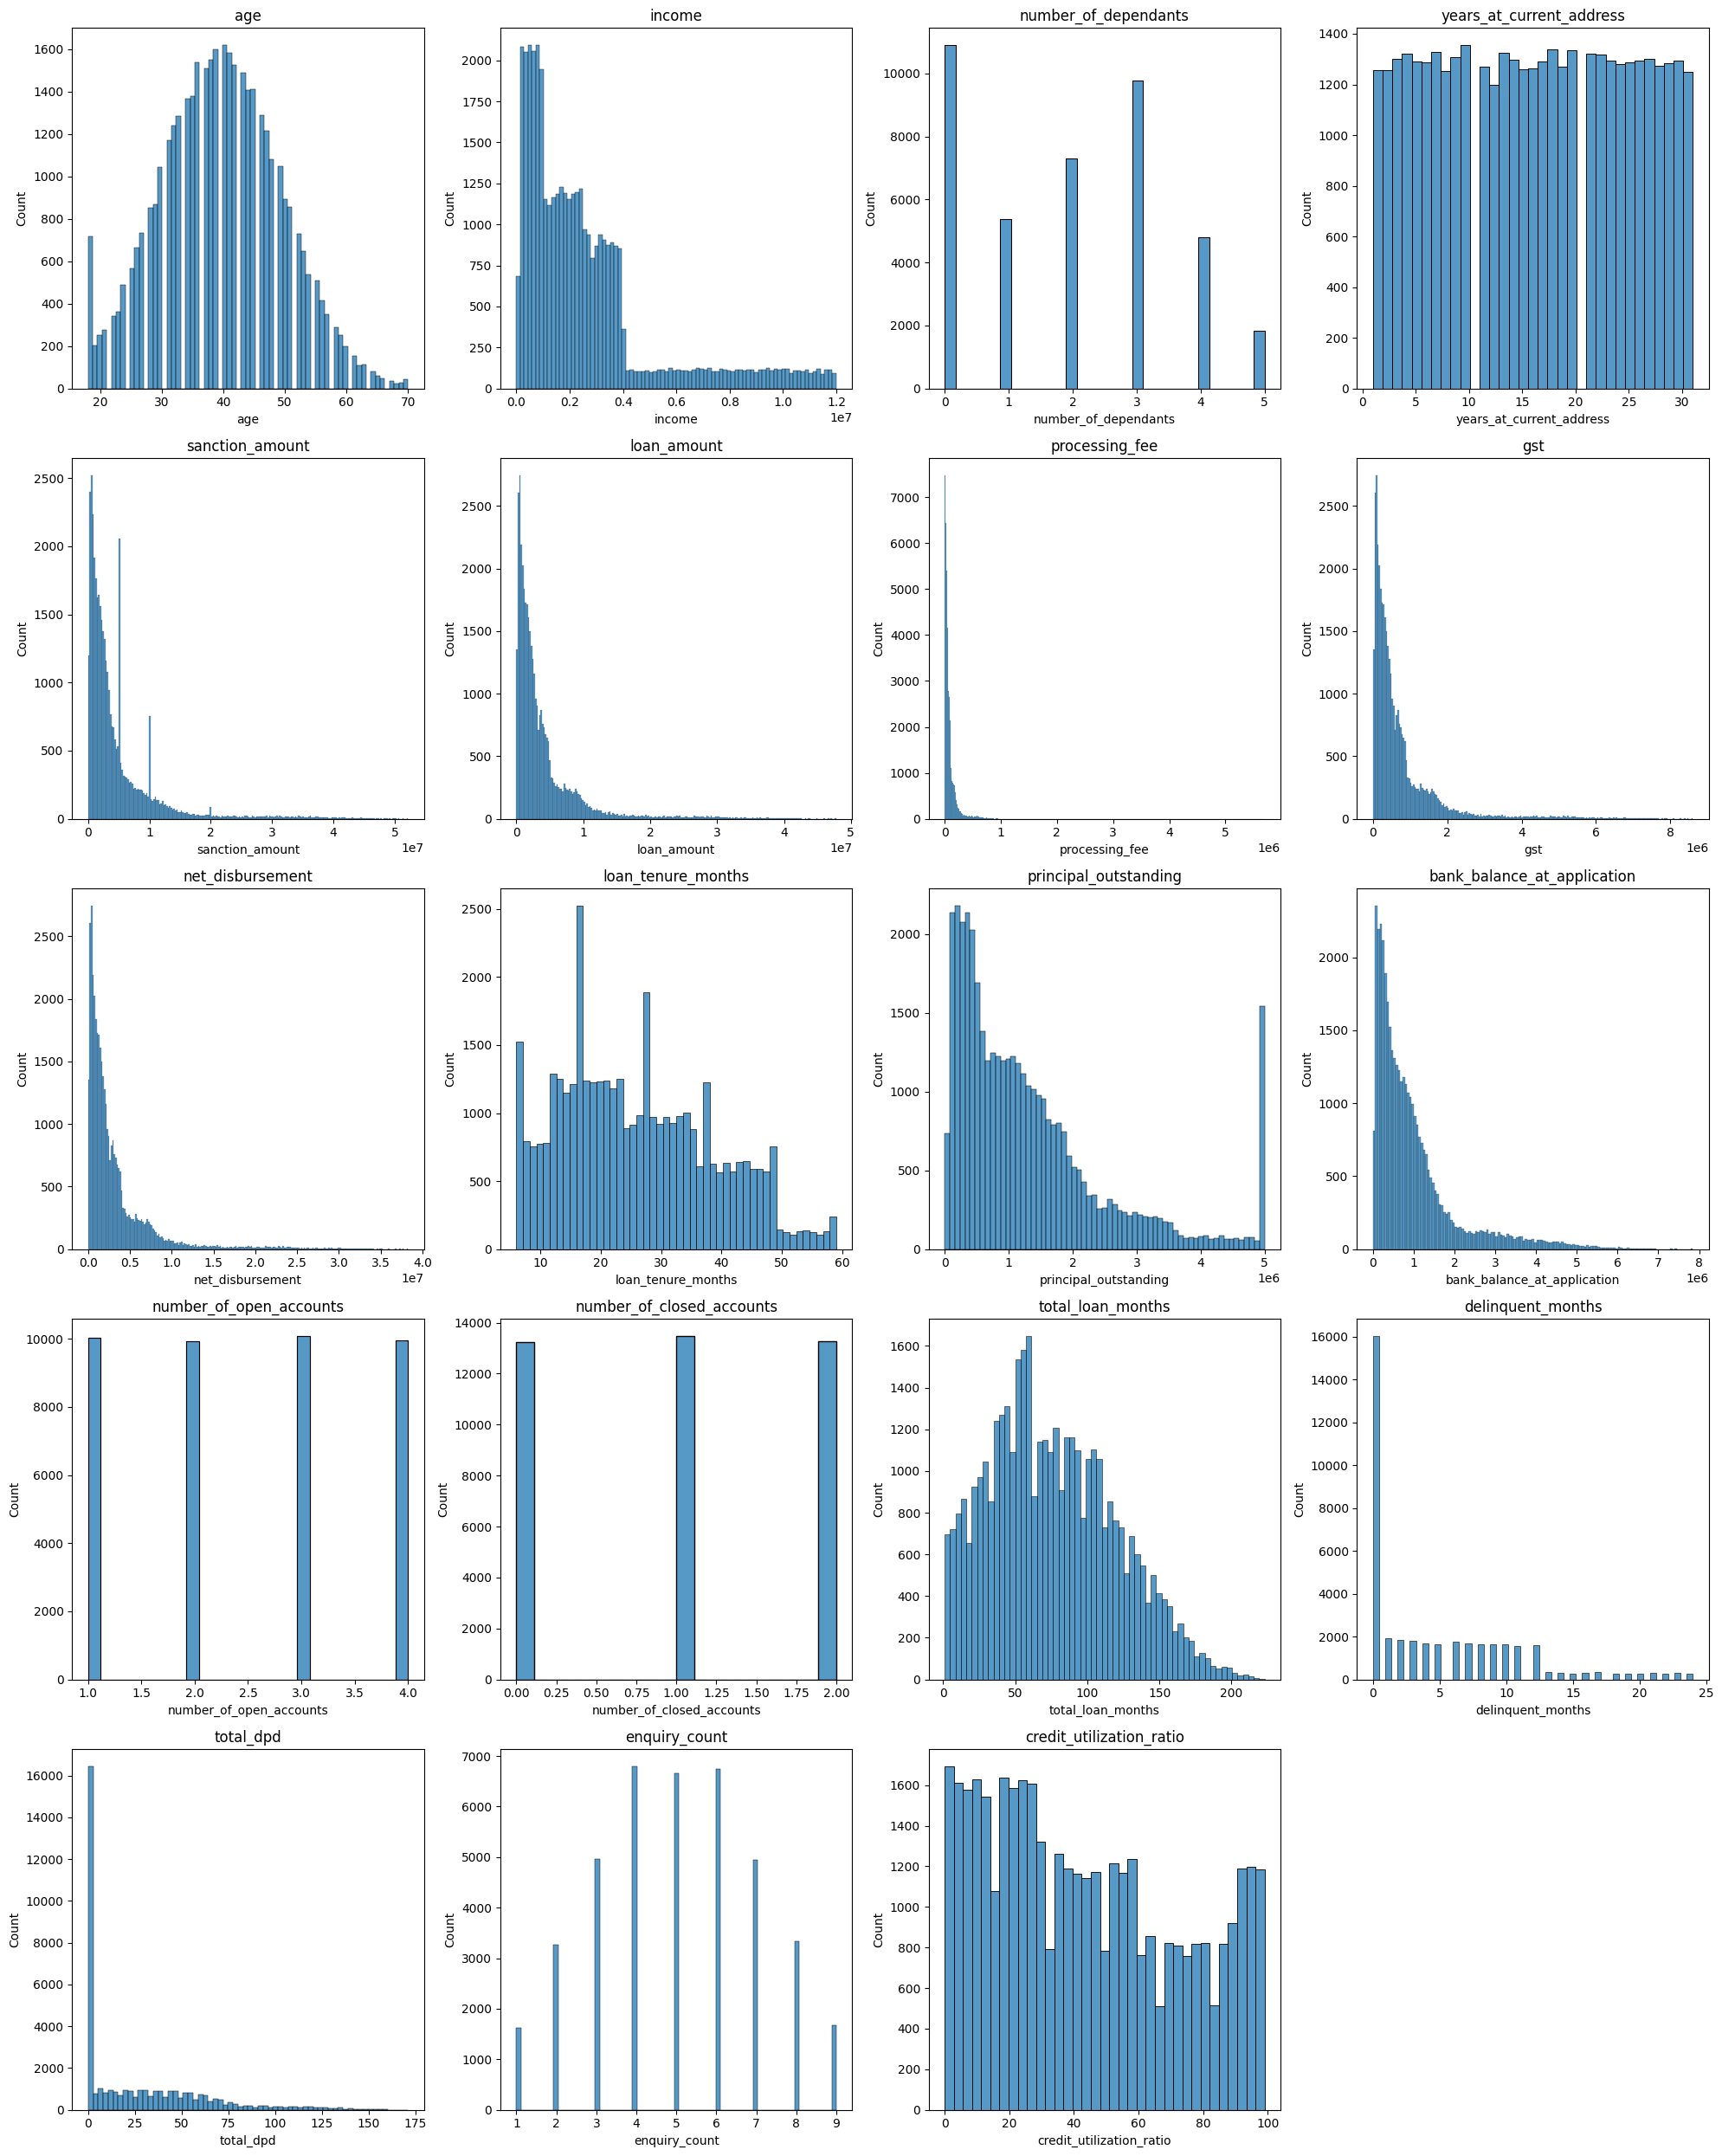

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

n_cols = 4
n_rows = math.ceil(len(numerical_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5 * n_rows))

axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.histplot(df_train[col], ax=axes[i])
    axes[i].set_title(col)

# Remove empty plots
for i in range(len(numerical_cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

In [35]:
df_train.processing_fee.describe()

count    4.000000e+04
mean     8.054547e+04
std      1.154181e+05
min      0.000000e+00
25%      1.938000e+04
50%      4.480000e+04
75%      9.256000e+04
max      5.698030e+06
Name: processing_fee, dtype: float64

In [36]:
df_train[(df_train.processing_fee / df_train.loan_amount) > 0.03][["loan_amount", "processing_fee"]]

,loan_amount,processing_fee
29305,2616000,3.036378e+06
28174,966000,1.214493e+06
9898,3626000,5.293544e+06
12294,4639000,5.698030e+06


In [37]:
df_train_1 = df_train[(df_train.processing_fee / df_train.loan_amount) < 0.03].copy()
df_train_1[(df_train_1.processing_fee / df_train_1.loan_amount) > 0.03][["loan_amount", "processing_fee"]]

,loan_amount,processing_fee


In [38]:
df_test = df_test[(df_test.processing_fee / df_test.loan_amount) < 0.03].copy()
df_test.shape

(9994, 33)

In [39]:
categorical_cols

['gender',
 'marital_status',
 'employment_status',
 'residence_type',
 'city',
 'state',
 'zipcode',
 'loan_purpose',
 'loan_type',
 'default']

In [42]:
for col in categorical_cols:
    print(col ,"-->", df_train_1[col].unique())

gender --> <ArrowStringArray>
['M', 'F']
Length: 2, dtype: str
marital_status --> <ArrowStringArray>
['Married', 'Single']
Length: 2, dtype: str
employment_status --> <ArrowStringArray>
['Salaried', 'Self-Employed']
Length: 2, dtype: str
residence_type --> <ArrowStringArray>
['Owned', 'Rented', 'Mortgage']
Length: 3, dtype: str
city --> <ArrowStringArray>
[  'Kolkata', 'Ahmedabad',    'Mumbai',   'Lucknow',      'Pune',   'Chennai',
     'Delhi', 'Hyderabad',    'Jaipur', 'Bangalore']
Length: 10, dtype: str
state --> <ArrowStringArray>
[  'West Bengal',       'Gujarat',   'Maharashtra', 'Uttar Pradesh',
    'Tamil Nadu',         'Delhi',     'Telangana',     'Rajasthan',
     'Karnataka']
Length: 9, dtype: str
zipcode --> [700001 380001 400001 226001 411001 600001 110001 500001 302001 560001]
loan_purpose --> <ArrowStringArray>
['Auto', 'Education', 'Home', 'Personal', 'Personaal']
Length: 5, dtype: str
loan_type --> <ArrowStringArray>
['Secured', 'Unsecured']
Length: 2, dtype: str
def

In [43]:
df_train_1['loan_purpose'] = df_train_1['loan_purpose'].replace('Personaal', 'Personal')
df_test['loan_purpose'] = df_test['loan_purpose'].replace('Personaal', 'Personal')
df_train_1['loan_purpose'].unique()

<ArrowStringArray>
['Auto', 'Education', 'Home', 'Personal']
Length: 4, dtype: str